In [1]:
import pandas as pd
import numpy as np

In [2]:
LPG_Sales = pd.read_csv('..\Data\LPG_Sales_Concatenated.csv')
LPG_Sales.head()


,S/No,Receipt No,Item,Description of Item,Measure Unit (Kg),Quantity,Total Kg,Unit Price (NGN),Total Amount (NGN),Payment Type,Customer No,Voucher Amount (NGN),Date,Posted Year (as shown),Source File
0,10,105310,LPG (Gas),End-User (Member),3.00,1,3.00,1400.0,4200.0,CASH,0,0,11/8/2024,2024,Sales Report.PDF
1,9,105322,LPG (Gas),End-User (Member),492.73,1,492.73,1400.0,689822.0,CASH,0,0,11/8/2024,2024,Sales Report.PDF
2,3,105328,LPG (Gas),End-User (Member),8.57,1,8.57,1400.0,11998.0,CASH,0,0,11/8/2024,2024,Sales Report.PDF
3,4,105328,LPG (Gas),End-User (Member),12.50,1,12.50,1400.0,17500.0,CASH,0,0,11/8/2024,2024,Sales Report.PDF
4,5,105328,LPG (Gas),End-User (Member),3.57,1,3.57,1400.0,4998.0,CASH,0,0,11/8/2024,2024,Sales Report.PDF


In [3]:
LPG_Sales.shape

(20983, 15)

In [4]:
LPG_Sales.describe()

,S/No,Receipt No,Measure Unit (Kg),Quantity,Total Kg,Unit Price (NGN),Total Amount (NGN),Customer No,Voucher Amount (NGN),Posted Year (as shown)
count,20983.000000,20983.000000,20983.000000,20983.000000,20983.000000,20983.000000,2.098300e+04,20983.0,20983.0,20983.000000
mean,35.218606,105981.278273,7.981581,1.047276,8.476627,1296.468253,1.096406e+04,0.0,0.0,1334.882905
std,33.615660,993.032286,15.038407,0.360518,16.081747,140.354331,2.125932e+04,0.0,0.0,884.286349
min,1.000000,79403.000000,0.000000,0.000000,0.000000,0.010000,0.000000e+00,0.0,0.0,202.000000
25%,15.000000,105463.000000,3.330000,1.000000,3.500000,1240.000000,4.500000e+03,0.0,0.0,202.000000
50%,29.000000,105745.000000,6.000000,1.000000,6.000000,1250.000000,7.500000e+03,0.0,0.0,2025.000000
75%,46.000000,106295.000000,12.000000,1.000000,12.000000,1400.000000,1.500000e+04,0.0,0.0,2025.000000
max,357.000000,108869.000000,834.930000,19.000000,834.930000,1500.000000,1.001916e+06,0.0,0.0,2026.000000


In [5]:
LPG_Sales.columns

Index(['S/No', 'Receipt No', 'Item', 'Description of Item',
       'Measure Unit (Kg)', 'Quantity', 'Total Kg', 'Unit Price (NGN)',
       'Total Amount (NGN)', 'Payment Type', 'Customer No',
       'Voucher Amount (NGN)', 'Date', 'Posted Year (as shown)',
       'Source File'],
      dtype='object')

In [6]:
LPG_Sales.isnull().sum()

S/No                       0
Receipt No                 0
Item                       8
Description of Item       17
Measure Unit (Kg)          0
Quantity                   0
Total Kg                   0
Unit Price (NGN)           0
Total Amount (NGN)         0
Payment Type              10
Customer No                0
Voucher Amount (NGN)       0
Date                       0
Posted Year (as shown)     0
Source File               13
dtype: int64

In [7]:
New_Features = ['Receipt No', 'Item', 'Description of Item', 'Measure Unit (Kg)', 'Quantity', 'Total Kg', 'Unit Price (NGN)', 'Total Amount (NGN)', 'Date',]
LPG_Sales = LPG_Sales.drop([c for c in LPG_Sales.columns if c not in New_Features], axis=1)

In [8]:
LPG_Sales.columns

Index(['Receipt No', 'Item', 'Description of Item', 'Measure Unit (Kg)',
       'Quantity', 'Total Kg', 'Unit Price (NGN)', 'Total Amount (NGN)',
       'Date'],
      dtype='object')

In [9]:
LPG_Sales.dropna(inplace=True, axis=0)

In [10]:
LPG_Sales.shape

(20958, 9)

In [11]:
Day_of_Week = pd.DatetimeIndex(LPG_Sales['Date']).dayofweek
Day = pd.DatetimeIndex(LPG_Sales['Date']).day
month = pd.DatetimeIndex(LPG_Sales['Date']).month
year = pd.DatetimeIndex(LPG_Sales['Date']).year

In [12]:
new_LPG_Sales = LPG_Sales.assign(DayofWeek = Day_of_Week,
                                 Day=Day,
                                 Month=month,
                                 Year=year)

In [13]:
new_LPG_Sales.head(200)

,Receipt No,Item,Description of Item,Measure Unit (Kg),Quantity,Total Kg,Unit Price (NGN),Total Amount (NGN),Date,DayofWeek,Day,Month,Year
0,105310,LPG (Gas),End-User (Member),3.00,1,3.00,1400.0,4200.0,11/8/2024,4,8,11,2024
1,105322,LPG (Gas),End-User (Member),492.73,1,492.73,1400.0,689822.0,11/8/2024,4,8,11,2024
2,105328,LPG (Gas),End-User (Member),8.57,1,8.57,1400.0,11998.0,11/8/2024,4,8,11,2024
3,105328,LPG (Gas),End-User (Member),12.50,1,12.50,1400.0,17500.0,11/8/2024,4,8,11,2024
4,105328,LPG (Gas),End-User (Member),3.57,1,3.57,1400.0,4998.0,11/8/2024,4,8,11,2024
...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,105516,LPG (Gas),End-User (Member),7.14,1,7.14,1400.0,9996.0,11/12/2024,1,12,11,2024
196,105517,LPG (Gas),End-User (Member),2.00,1,2.00,1400.0,2800.0,11/12/2024,1,12,11,2024
197,105519,LPG (Gas),End-User (Member),2.00,1,2.00,1400.0,2800.0,11/12/2024,1,12,11,2024
198,105519,LPG (Gas),End-User (Member),12.50,1,12.50,1400.0,17500.0,11/12/2024,1,12,11,2024


In [14]:
import matplotlib.pyplot as plt

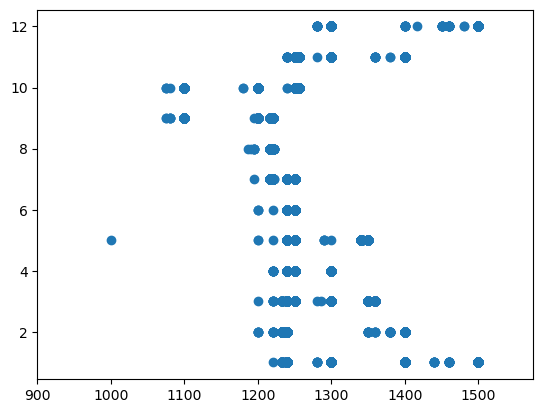

In [15]:
price = new_LPG_Sales['Unit Price (NGN)']
month = new_LPG_Sales['Month']
plt.scatter(price, month)
plt.xlim(900)
plt.show()

Text(0, 0.5, 'LPG Price')

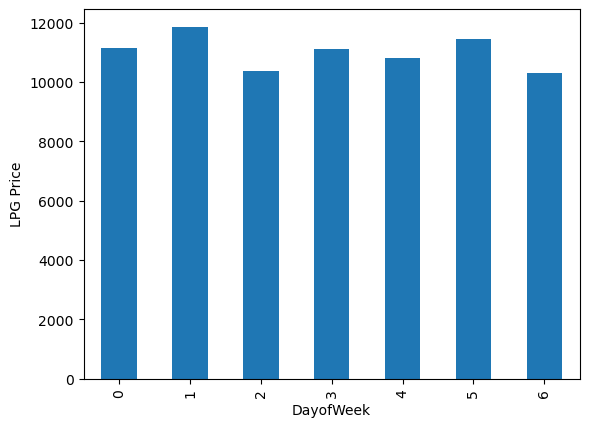

In [16]:
new_LPG_Sales.groupby(['DayofWeek'])['Total Amount (NGN)'].mean().plot(kind='bar')
plt.ylabel("LPG Price")

Text(0, 0.5, 'LPG Price')

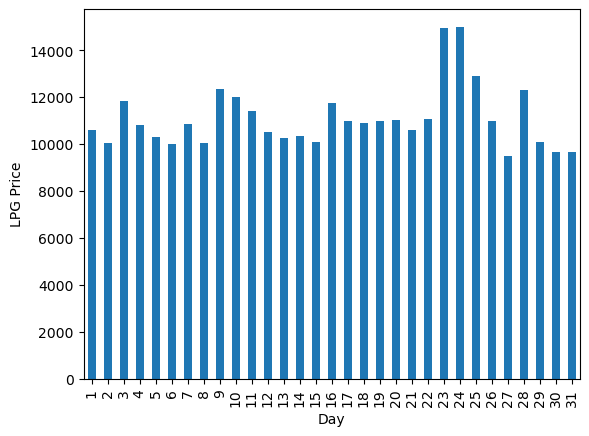

In [17]:
new_LPG_Sales.groupby(['Day'])['Total Amount (NGN)'].mean().plot(kind='bar')
plt.ylabel("LPG Price")

Text(0, 0.5, 'LPG Price')

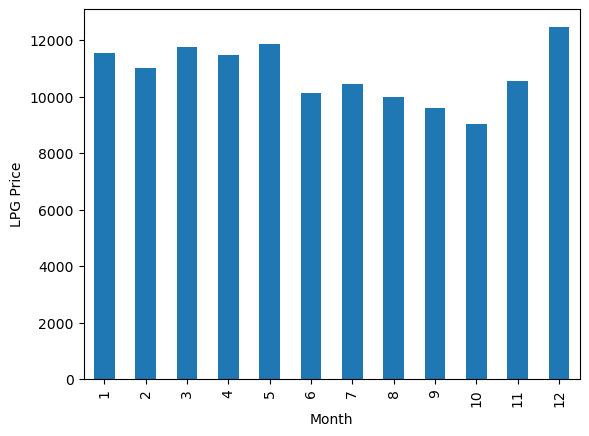

In [18]:
new_LPG_Sales.groupby(['Month'])['Total Amount (NGN)'].mean().plot(kind='bar')
plt.ylabel("LPG Price")

Text(0.5, 0, 'Year')

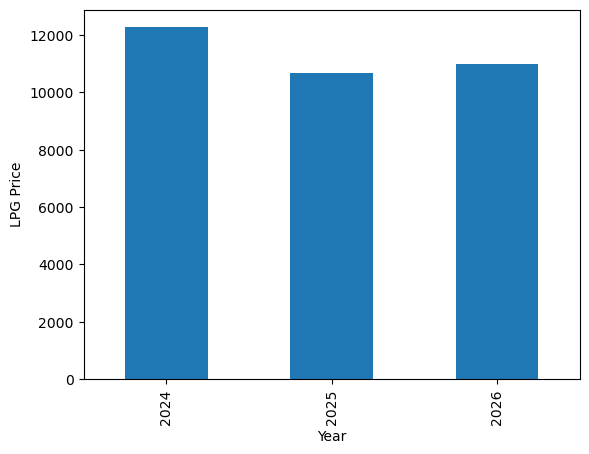

In [19]:
new_LPG_Sales.groupby(['Year'])['Total Amount (NGN)'].mean().plot(kind='bar')
plt.ylabel("LPG Price")
plt.xlabel("Year")


<Axes: xlabel='Description of Item'>

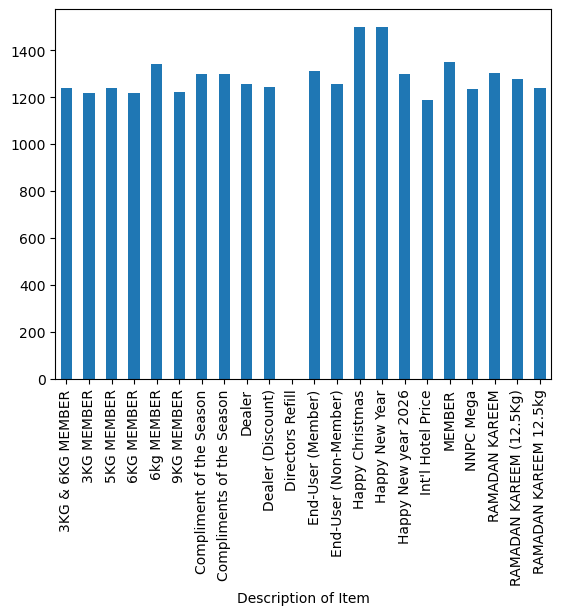

In [20]:
new_LPG_Sales.groupby(['Description of Item'])['Unit Price (NGN)'].mean().plot(kind='bar')

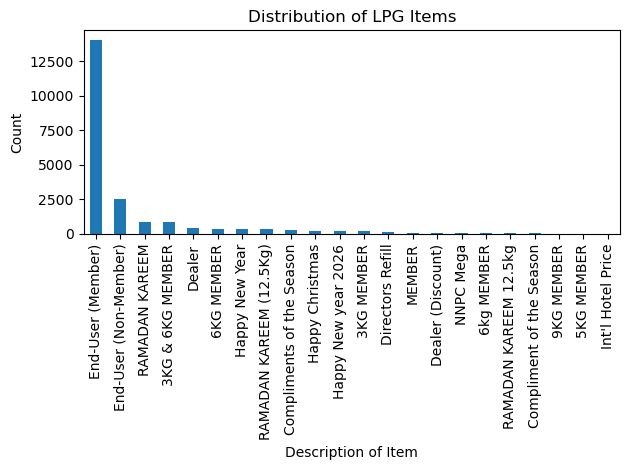

In [21]:
new_LPG_Sales['Description of Item'].value_counts().plot(kind='bar')
plt.xlabel('Description of Item')
plt.ylabel('Count')
plt.title('Distribution of LPG Items')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [22]:
print(new_LPG_Sales['Year'].corr(new_LPG_Sales['Unit Price (NGN)']))


-0.3663915772469302


In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error


In [24]:
new_LPG_Sales.columns

Index(['Receipt No', 'Item', 'Description of Item', 'Measure Unit (Kg)',
       'Quantity', 'Total Kg', 'Unit Price (NGN)', 'Total Amount (NGN)',
       'Date', 'DayofWeek', 'Day', 'Month', 'Year'],
      dtype='object')

In [25]:
# Target: what we want to predict
y = new_LPG_Sales['Total Amount (NGN)']

# feature for practice model
num_features = ['Quantity', 'Measure Unit (Kg)', 'Unit Price (NGN)', 'Month', 'DayofWeek', 'Day']

Categorical_features = ['Description of Item']

X = new_LPG_Sales[num_features+Categorical_features]

# Split beforefitting preprocessing or model steps
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

# process nnumeric and categorical features seperately
numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy='median'))])
categorical_pipeline = Pipeline([("imputer", SimpleImputer(strategy='most_frequent')),( "encoder", OneHotEncoder(handle_unknown='ignore'))])

preprocessor = ColumnTransformer([('num', numeric_pipeline, num_features),('cat', categorical_pipeline, Categorical_features)])

model = Pipeline([('preprocessor', preprocessor),('regressor', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))])

model.fit(X_train, y_train)
predictions = model.predict(X_test)



In [26]:
print ("MAE:", mean_absolute_error(y_test, predictions))
print ("RMSE:", mean_squared_error (y_test, predictions)**0.5)
print("R²:", r2_score(y_test, predictions))

MAE: 171.5046475190848
RMSE: 3315.5987570503758
R²: 0.9705141727282506


In [27]:
mse = np.sqrt(mean_squared_error(y_test,predictions))
print(f'Mean error: {mse:3.3} ({mse/np.mean(predictions)*100:3.3}%)')

Mean error: 3.32e+03 (29.4%)


In [28]:
score = model.score(X_train,y_train)
print('Model determination: ', score)

Model determination:  0.9946900237054074


In [29]:
USD_Rates = pd.read_csv(r'..\Data\USD-NGN Daily trend.csv')

In [30]:
USD_Rates.head()

,Date,USD-NGN
0,08/11/2024,1667.58
1,10/11/2024,1667.58
2,11/11/2024,1672.77
3,12/11/2024,1672.18
4,13/11/2024,1676.96


In [31]:
USD_Rates.shape

(478, 2)

In [32]:
# Convert both Date Columns to datetime
new_LPG_Sales["Date"]= pd.to_datetime(new_LPG_Sales["Date"],format="mixed", dayfirst=False).dt.normalize()

USD_Rates["Date"]= pd.to_datetime(USD_Rates["Date"], format="mixed", dayfirst=False).dt.normalize()

In [33]:
# Merge the datasets using Date
merged = pd.merge (new_LPG_Sales, USD_Rates, on="Date", how="left", validate="many_to_one")

In [34]:
merged

,Receipt No,Item,Description of Item,Measure Unit (Kg),Quantity,Total Kg,Unit Price (NGN),Total Amount (NGN),Date,DayofWeek,Day,Month,Year,USD-NGN
0,105310,LPG (Gas),End-User (Member),3.00,1,3.00,1400.0,4200.0,2024-11-08,4,8,11,2024,NaN
1,105322,LPG (Gas),End-User (Member),492.73,1,492.73,1400.0,689822.0,2024-11-08,4,8,11,2024,NaN
2,105328,LPG (Gas),End-User (Member),8.57,1,8.57,1400.0,11998.0,2024-11-08,4,8,11,2024,NaN
3,105328,LPG (Gas),End-User (Member),12.50,1,12.50,1400.0,17500.0,2024-11-08,4,8,11,2024,NaN
4,105328,LPG (Gas),End-User (Member),3.57,1,3.57,1400.0,4998.0,2024-11-08,4,8,11,2024,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20953,106418,LPG (Gas),3KG & 6KG MEMBER,2.96,1,2.96,1350.0,3996.0,2026-05-19,1,19,5,2026,1371.0
20954,106419,LPG (Gas),3KG & 6KG MEMBER,5.00,1,5.00,1350.0,6750.0,2026-05-19,1,19,5,2026,1371.0
20955,106420,LPG (Gas),3KG & 6KG MEMBER,5.00,1,5.00,1350.0,6750.0,2026-05-19,1,19,5,2026,1371.0
20956,106421,LPG (Gas),End-User (Member),12.50,1,12.50,1340.0,16750.0,2026-05-19,1,19,5,2026,1371.0


In [35]:
merged.isnull().sum()

Receipt No                0
Item                      0
Description of Item       0
Measure Unit (Kg)         0
Quantity                  0
Total Kg                  0
Unit Price (NGN)          0
Total Amount (NGN)        0
Date                      0
DayofWeek                 0
Day                       0
Month                     0
Year                      0
USD-NGN                4362
dtype: int64

In [36]:
LPG_with_USD= merged.dropna(axis=0)

In [63]:
LPG_with_USD.head()

,Receipt No,Item,Description of Item,Measure Unit (Kg),Quantity,Total Kg,Unit Price (NGN),Total Amount (NGN),Date,DayofWeek,Day,Month,Year,USD-NGN
124,105445,LPG (Gas),End-User (Member),5.0,1,5.0,1400.0,7000.0,2024-11-11,0,11,11,2024,1672.77
174,105495,LPG (Gas),End-User (Member),5.0,1,5.0,1400.0,7000.0,2024-11-11,0,11,11,2024,1672.77
173,105494,LPG (Gas),End-User (Member),12.5,1,12.5,1400.0,17500.0,2024-11-11,0,11,11,2024,1672.77
172,105493,LPG (Gas),End-User (Member),3.0,1,3.0,1400.0,4200.0,2024-11-11,0,11,11,2024,1672.77
171,105492,LPG (Gas),End-User (Member),6.0,1,6.0,1400.0,8400.0,2024-11-11,0,11,11,2024,1672.77


In [38]:
LPG_with_USD.isnull().sum()

Receipt No             0
Item                   0
Description of Item    0
Measure Unit (Kg)      0
Quantity               0
Total Kg               0
Unit Price (NGN)       0
Total Amount (NGN)     0
Date                   0
DayofWeek              0
Day                    0
Month                  0
Year                   0
USD-NGN                0
dtype: int64

In [39]:
LPG_with_USD.to_csv("LPG_Sales_with_USD", index=False)

In [40]:
# Convert date to datetime
LPG_with_USD['Date'] = pd.to_datetime(LPG_with_USD['Date'])

C:\Users\HP\AppData\Local\Temp\ipykernel_1916\3388190207.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  LPG_with_USD['Date'] = pd.to_datetime(LPG_with_USD['Date'])


In [41]:
# Remove transactions with zero or invalid quantity
LPG_with_USD = LPG_with_USD[LPG_with_USD["Total Kg"]>0].copy()

In [42]:
# Sort dtat chronological
LPG_with_USD = LPG_with_USD.sort_values("Date")

In [43]:
# Aggregate transactions by date
LPG_daily = LPG_with_USD.groupby("Date").agg(
    Total_kg=("Total Kg","sum"),
    Total_Revenue=("Total Amount (NGN)","sum"),
    Transaction_count=("Receipt No","count"),
    USD_NGN=("USD-NGN","first")
).reset_index()

In [44]:
#Calculate weighted average LPG price
LPG_daily["Price/Kg"]=(LPG_daily["Total_Revenue"]/LPG_daily["Total_kg"])
# Sort Chronologically
LPG_daily = LPG_daily.sort_values("Date")

In [45]:
LPG_daily

,Date,Total_kg,Total_Revenue,Transaction_count,USD_NGN,Price/Kg
0,2024-11-11,516.90,721420.00,70,1672.77,1395.666473
1,2024-11-12,533.36,710324.26,71,1548.65,1331.791398
2,2024-11-13,309.73,433622.00,47,1676.96,1400.000000
3,2024-11-14,461.40,645960.00,50,1679.46,1400.000000
4,2024-11-15,311.62,436268.00,51,1665.32,1400.000000
...,...,...,...,...,...,...
290,2026-05-03,1713.64,2218667.34,115,1383.97,1294.710289
291,2026-05-05,298.16,400151.29,34,1364.91,1342.068990
292,2026-05-17,440.24,571689.15,51,1367.25,1298.585204
293,2026-05-18,443.41,539373.91,45,1370.02,1216.422521


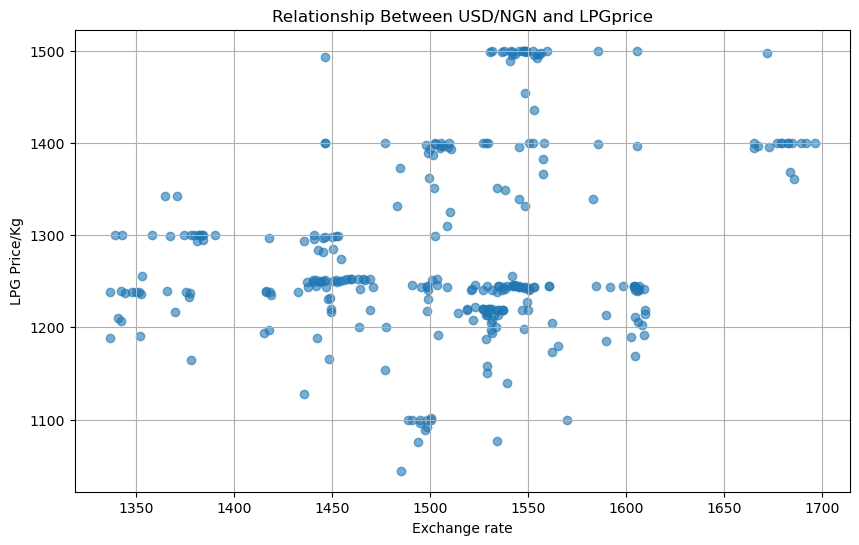

In [66]:
# create a scatter plot
plt.figure(figsize=(10,6))
plt.scatter(LPG_daily['USD_NGN'], LPG_daily['Price/Kg'], alpha=0.6)
plt.title("Relationship Between USD/NGN and LPGprice")
plt.xlabel("Exchange rate")
plt.ylabel("LPG Price/Kg")
plt.grid(True)

plt.show()

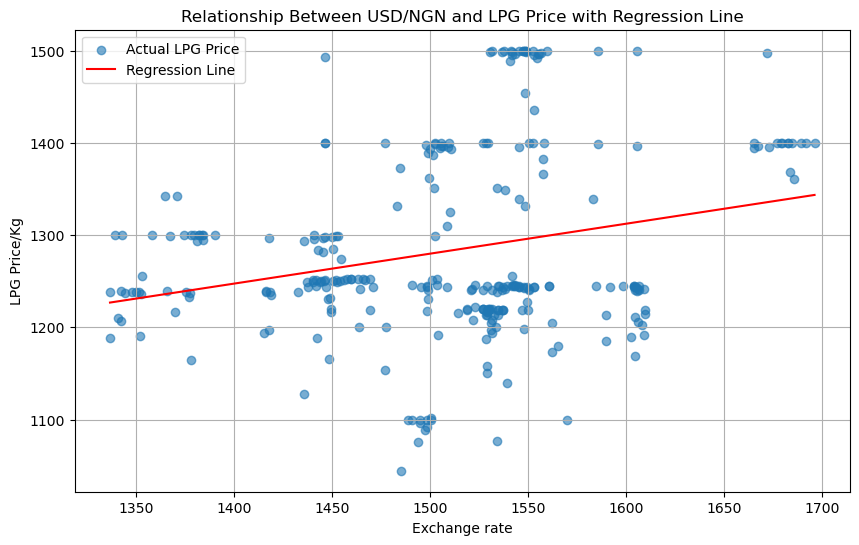

In [68]:
# Adding the regression line
    #Calculating the reression Coefficients
slope, intercept = np.polyfit(LPG_daily['USD_NGN'], LPG_daily['Price/Kg'], 1)

#Generate the regression line
x = np.linspace(LPG_daily['USD_NGN'].min(), LPG_daily['USD_NGN'].max(), 100)
y = slope * x + intercept

plt.figure(figsize=(10,6))

plt.scatter(LPG_daily['USD_NGN'], LPG_daily['Price/Kg'], alpha=0.6, label='Actual LPG Price')
plt.plot(x, y, color='red', label='Regression Line')
plt.title("Relationship Between USD/NGN and LPG Price with Regression Line")
plt.xlabel("Exchange rate")
plt.ylabel("LPG Price/Kg")
plt.legend()
plt.grid(True)
plt.show()

In [69]:
# Calculate the correlation
correlation = LPG_daily['USD_NGN'].corr(LPG_daily['Price/Kg'])
print(f"Correlation between USD/NGN and LPG Price/Kg: {correlation:.4f}")

Correlation between USD/NGN and LPG Price/Kg: 0.2522


In [46]:
# Save Dataset
LPG_daily.to_csv("Daily_LPG_ML_Dataset", index=False)

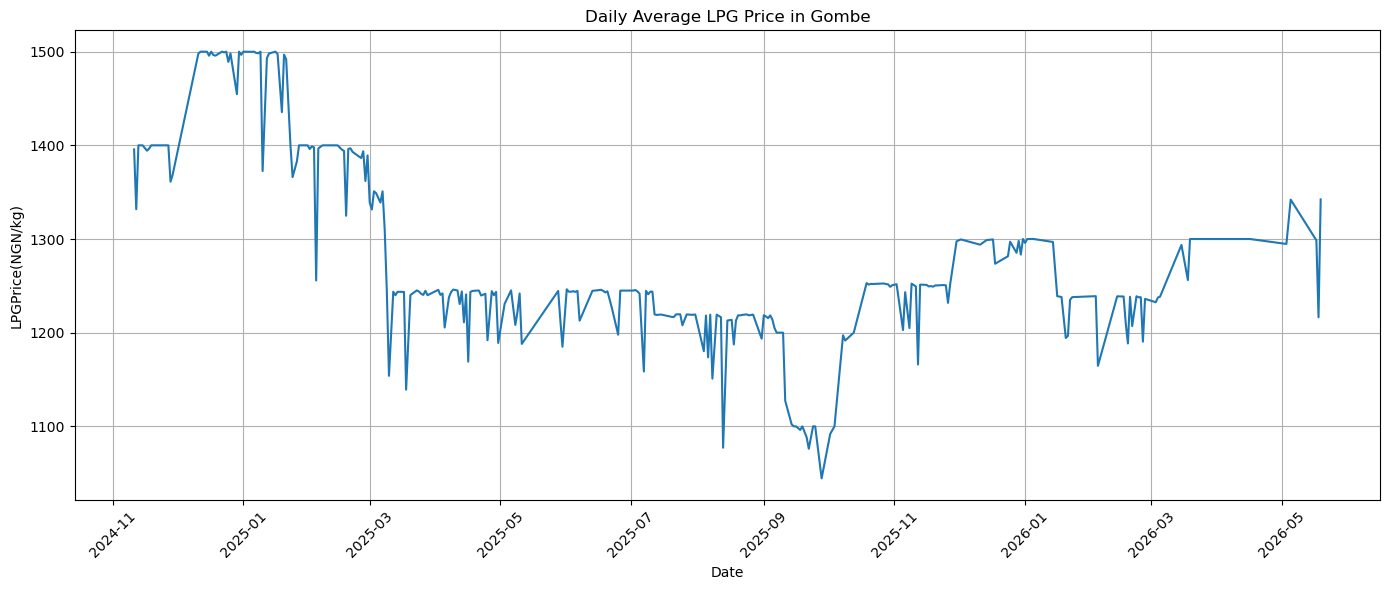

In [47]:
plt.figure(figsize=(14,6))
plt.plot(LPG_daily['Date'],LPG_daily["Price/Kg"])

plt.title("Daily Average LPG Price in Gombe")
plt.xlabel('Date')
plt.ylabel("LPGPrice(NGN/kg)")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [48]:
# importing Model
from sklearn.linear_model import LinearRegression

In [49]:
# create date features
LPG_daily["Month"] = LPG_daily["Date"].dt.month
LPG_daily["Day_of_Week"] = LPG_daily["Date"].dt.dayofweek

In [61]:
LPG_daily.head()

,Date,Total_kg,Total_Revenue,Transaction_count,USD_NGN,Price/Kg,Month,Day_of_Week
0,2024-11-11,516.90,721420.00,70,1672.77,1395.666473,11,0
1,2024-11-12,533.36,710324.26,71,1548.65,1331.791398,11,1
2,2024-11-13,309.73,433622.00,47,1676.96,1400.000000,11,2
3,2024-11-14,461.40,645960.00,50,1679.46,1400.000000,11,3
4,2024-11-15,311.62,436268.00,51,1665.32,1400.000000,11,4


In [51]:
# Selecting features and target
features = ["USD_NGN","Month","Day_of_Week"]
target = ["Price/Kg"]

model_data = LPG_daily.dropna(subset=features+target)

X1 = model_data[features]
y1 = model_data[target]

#split data
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.2, random_state=42)

# Create Linear Regression Model
pipeline = make_pipeline(PolynomialFeatures(2), LinearRegression())

# Train Model
pipeline.fit(X1_train, y1_train)

# Make prediction
predictions_1 = pipeline.predict(X1_test)

# evaluate model
mae = mean_absolute_error(y1_test, predictions_1)

rmse = np.sqrt(mean_squared_error(y1_test, predictions_1))

r2 = r2_score(y1_test, predictions_1)

In [52]:
print("LINEAR REGRESSION RESULT")
print("MAE:",round(mae,1))
print("RMSE:",round(rmse,2))
print("R2 Score:",round(r2,3))

LINEAR REGRESSION RESULT
MAE: 53.4
RMSE: 65.5
R2 Score: 0.626


In [70]:
mse = np.sqrt(mean_squared_error(y1_test,predictions_1))
print(f'Mean error: {mse:3.3} ({mse/np.mean(predictions_1)*100:3.3}%)')

Mean error: 65.5 (5.12%)


In [72]:
score = pipeline.score(X1_train,y1_train)
print('Model determination: ', score)

Model determination:  0.5421312449257341


In [56]:
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType
# Check the nnumber of input features
print("Number of features:", pipeline.n_features_in_)

# Define the input tensor
initial_type = [('float_input', FloatTensorType([None,3]))]

#Convert the trained model to ONNX
onnx_model = convert_sklearn(pipeline, initial_types=initial_type)

# Save the ONNX model
with open("./model.onnx", "wb") as f:
    f.write(onnx_model.SerializeToString())

print("ONNX model successfully saved!")

Number of features: 3
ONNX model successfully saved!


In [58]:
import onnx

onnx_model = onnx.load("./model.onnx")
onnx.checker.check_model(onnx_model)

print("ONNX model is valid!")

ONNX model is valid!


In [59]:
X1_train.head(100)

,USD_NGN,Month,Day_of_Week
97,1536.76001,3,4
63,1446.44995,2,2
17,1548.37000,12,3
215,1465.62000,10,1
219,1457.75000,10,1
...,...,...,...
35,1536.93994,1,1
28,1541.58000,12,3
142,1547.91003,6,3
181,1534.81995,8,1
